In [4]:
import numpy as np
import pandas as pd
from scipy.stats import ks_2samp, wasserstein_distance
from synthetic_data_generator import EnergySyntheticGenerator

In [5]:
df = pd.read_csv('../data/energy_consumption.csv')

In [6]:
gen = EnergySyntheticGenerator()
gen.fit(df)

/home/agubarev/predictive_analytics_simulation/.venv/lib/python3.13/site-packages/sdv/single_table/base.py:136: UserWarning: We strongly recommend saving the metadata using 'save_to_json' for replicability in future SDV versions.
  warnings.warn(


In [7]:
df_reference = gen.generate(n_rows=2000, seed=42)

df_drifted = gen.generate(
    n_rows=2000,
    temp_shift=4.5,       # Температура «уехала» вверх на +4.5°C
    occupancy_mult=1.35,  # Людей стало на 35% больше
    seed=99,
)

In [8]:
def calculate_psi(expected: pd.Series, actual: pd.Series, bins: int = 10) -> float:
    breakpoints = np.percentile(expected, np.linspace(0, 100, bins + 1))
    breakpoints = np.unique(breakpoints)

    expected_counts = np.histogram(expected, bins=breakpoints)[0] / len(expected)
    actual_counts = np.histogram(actual, bins=breakpoints)[0] / len(actual)

    expected_counts = np.clip(expected_counts, 1e-6, None)
    actual_counts = np.clip(actual_counts, 1e-6, None)

    return float(
        np.sum((actual_counts - expected_counts) * np.log(actual_counts / expected_counts))
    )

In [9]:
def detect_data_drift(df_ref: pd.DataFrame, df_curr: pd.DataFrame, num_cols: list) -> pd.DataFrame:
    report = []
    for col in num_cols:
        psi_val = calculate_psi(df_ref[col], df_curr[col])
        ks_stat, ks_pval = ks_2samp(df_ref[col], df_curr[col])
        w_dist = wasserstein_distance(df_ref[col], df_curr[col])

        status = (
            'CRITICAL (Сильный дрифт)'
            if psi_val >= 0.25
            else 'WARNING (Умеренный)'
            if psi_val >= 0.1
            else 'OK (Стабильно)'
        )

        report.append({
            'Feature': col,
            'PSI': round(psi_val, 4),
            'KS p-value': round(ks_pval, 4),
            'Wasserstein': round(w_dist, 3),
            'Status': status,
        })
    return pd.DataFrame(report)

In [10]:
features_to_check = ['Temperature', 'Humidity', 'Occupancy', 'RenewableEnergy']
drift_report = detect_data_drift(df_reference, df_drifted, features_to_check)
print('\n--- ОТЧЕТ ПО DATA DRIFT ---')
print(drift_report.to_string(index=False))


--- ОТЧЕТ ПО DATA DRIFT ---
        Feature    PSI  KS p-value  Wasserstein                   Status
    Temperature 4.6167      0.0000        4.178 CRITICAL (Сильный дрифт)
       Humidity 0.0100      0.2918        0.462           OK (Стабильно)
      Occupancy 2.2414      0.0000        1.616 CRITICAL (Сильный дрифт)
RenewableEnergy 0.0052      0.4838        0.317           OK (Стабильно)


Плавный Data drift

In [12]:
from catboost import CatBoostRegressor

In [11]:
def prepare_features(df_input: pd.DataFrame):
    data = df_input.copy()
    data['Timestamp'] = pd.to_datetime(data['Timestamp'])
    data['Hour'] = data['Timestamp'].dt.hour
    data['Month'] = data['Timestamp'].dt.month
    data['Temp_dist_22'] = np.abs(data['Temperature'] - 22.0)
    data['Occupancy_density'] = data['Occupancy'] / (data['SquareFootage'] + 1.0)
    data['Renewable_per_sqft'] = data['RenewableEnergy'] / (
        data['SquareFootage'] + 1.0
    )

    X = data.drop(columns=['Timestamp', 'EnergyConsumption'])
    y = data['EnergyConsumption']

    cat_cols = X.select_dtypes(
        include=['object', 'category', 'bool']
    ).columns.tolist()
    for col in cat_cols:
        X[col] = X[col].astype(str).fillna('Missing')

    return X, y, cat_cols

df_train_3k = gen.generate(n_rows=3000, seed=42)
X_train, y_train, cat_features = prepare_features(df_train_3k)

In [13]:
production_model = CatBoostRegressor(
    iterations=1500,
    learning_rate=0.03,
    depth=4,
    l2_leaf_reg=5,
    loss_function='RMSE',
    random_seed=42,
    verbose=0,
    allow_writing_files=False,
)
production_model.fit(X_train, y_train, cat_features=cat_features)

CatBoostRegressor(allow_writing_files=False, depth=4, iterations=1500, l2_leaf_reg=5, learning_rate=0.03, loss_function='RMSE', random_seed=42, verbose=0)

In [14]:
from sklearn.metrics import mean_absolute_error, r2_score

# 2. Генерируем 2000 стабильных строк (имитация нормальной работы в продакшене)
df_stable_2k = gen.generate(n_rows=2000, seed=100)

# Разбиваем эти 2000 строк на батчи по 200 строк, чтобы отслеживать динамику с самого начала
batch_size = 200
history_records = []

for i in range(0, len(df_stable_2k), batch_size):
    batch_df = df_stable_2k.iloc[i : i + batch_size]
    X_batch, y_batch, _ = prepare_features(batch_df)
    preds = production_model.predict(X_batch)

    history_records.append({
        'batch_id': len(history_records) + 1,
        'row_end': (len(history_records) + 1) * batch_size,
        'phase': '1. Стабильный период (Без дрифта)',
        'drift_intensity': 0.0,
        'MAE': mean_absolute_error(y_batch, preds),
        'R2': r2_score(y_batch, preds),
    })

# Считаем общие эталонные метрики на всех 2000 строках
X_stable_all, y_stable_all, _ = prepare_features(df_stable_2k)
preds_stable_all = production_model.predict(X_stable_all)

baseline_mae = mean_absolute_error(y_stable_all, preds_stable_all)
baseline_r2 = r2_score(y_stable_all, preds_stable_all)

print('Шаг 2 завершен: эталонные метрики на 2000 стабильных строках зафиксированы.')
print(f'Baseline MAE: {baseline_mae:.3f}')
print(f'Baseline R²:  {baseline_r2:.4f}')

Шаг 2 завершен: эталонные метрики на 2000 стабильных строках зафиксированы.
Baseline MAE: 4.117
Baseline R²:  0.5935


In [15]:
n_drift_total = 4000
n_batches = n_drift_total // batch_size  # 20 шагов деградации

for step in range(1, n_batches + 1):
    # Коэффициент силы дрифта плавно растет от 0.05 (5%) до 1.0 (100%)
    intensity = step / n_batches

    # А. DATA DRIFT: температура плавно уезжает до +6°C, заполняемость растет до +40%
    current_temp_shift = 6.0 * intensity
    current_occ_mult = 1.0 + 0.4 * intensity

    batch_drift = gen.generate(
        n_rows=batch_size,
        temp_shift=current_temp_shift,
        occupancy_mult=current_occ_mult,
        seed=200 + step,
    )

    # Учитываем физический отклик на экстремальную жару выше 30°C (деревья этого не видели на train)
    overheat_mask = batch_drift['Temperature'] > 30.0
    batch_drift.loc[overheat_mask, 'EnergyConsumption'] += (
        batch_drift.loc[overheat_mask, 'Temperature'] - 30.0
    ) * 2.2

    # Б. CONCEPT DRIFT: плавная деградация оборудования (кондиционер начинает жрать до +15 кВт лишнего)
    hvac_on_mask = batch_drift['HVACUsage'] == 'On'
    batch_drift.loc[hvac_on_mask, 'EnergyConsumption'] += 15.0 * intensity

    # Предсказываем ПЕРВОНАЧАЛЬНЫМ бустингом без переобучения
    X_batch, y_batch, _ = prepare_features(batch_drift)
    preds = production_model.predict(X_batch)

    history_records.append({
        'batch_id': len(history_records) + 1,
        'row_end': (len(history_records) + 1) * batch_size,
        'phase': '2. Плавный Data + Concept Drift',
        'drift_intensity': round(intensity * 100, 1),
        'MAE': mean_absolute_error(y_batch, preds),
        'R2': r2_score(y_batch, preds),
    })

metrics_df = pd.DataFrame(history_records)
print(
    'Шаг 3 завершен: прогнано 4000 строк с нарастающим дрифтом (20 батчей по 200 строк).'
)
print(metrics_df.tail(5).to_string(index=False))

Шаг 3 завершен: прогнано 4000 строк с нарастающим дрифтом (20 батчей по 200 строк).
 batch_id  row_end                           phase  drift_intensity       MAE        R2
       26     5200 2. Плавный Data + Concept Drift             80.0  9.775600 -0.070686
       27     5400 2. Плавный Data + Concept Drift             85.0  9.991853 -0.243502
       28     5600 2. Плавный Data + Concept Drift             90.0 10.836896 -0.296560
       29     5800 2. Плавный Data + Concept Drift             95.0 12.191553 -0.477620
       30     6000 2. Плавный Data + Concept Drift            100.0 12.122617 -0.346141


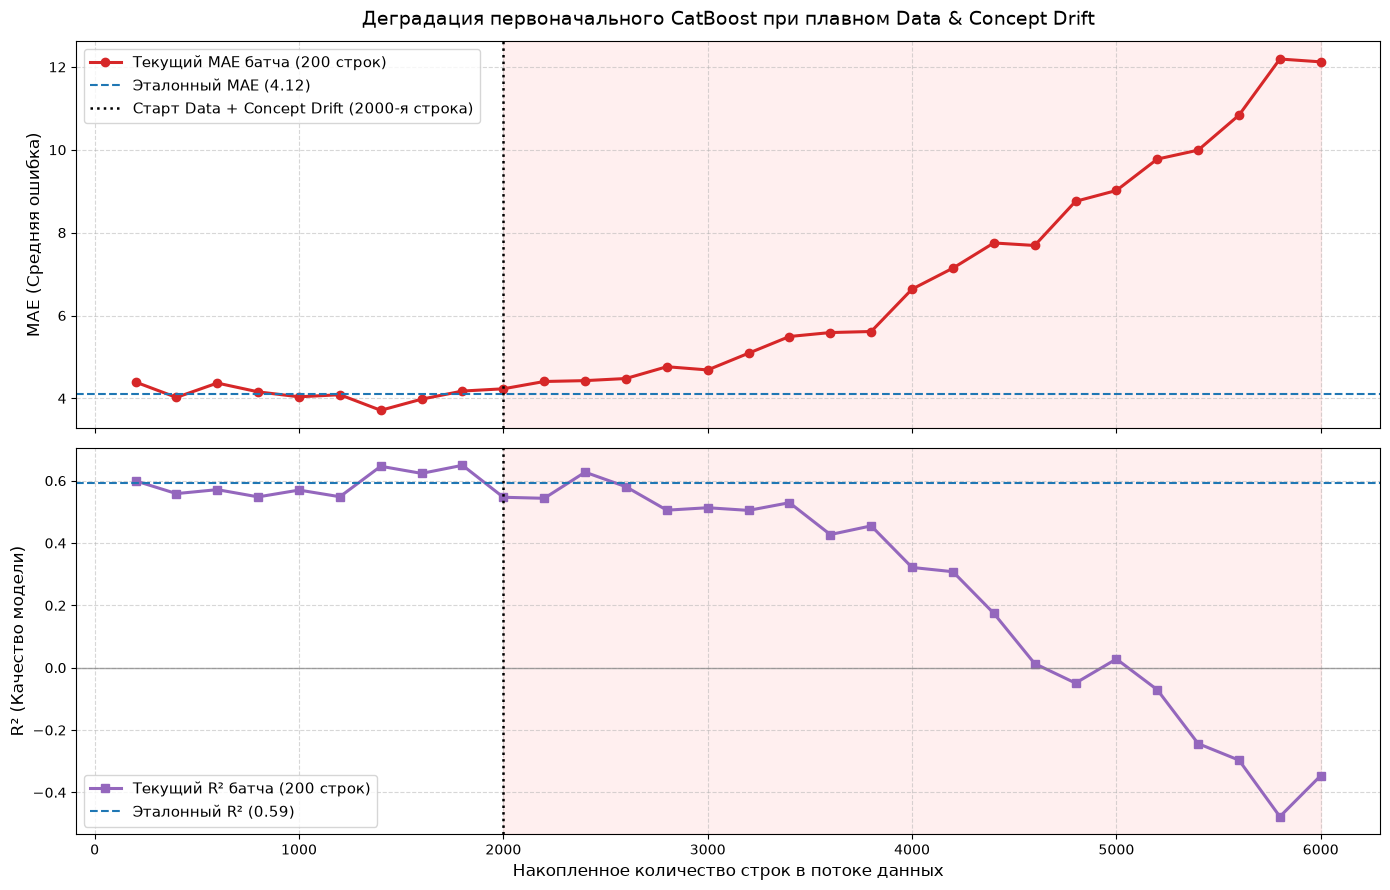

In [17]:
import matplotlib.pyplot as plt

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 9), sharex=True)

# Граница начала дрифта (после 2000-й строки)
drift_start_row = 2000

# --- График 1: Рост ошибки MAE ---
ax1.plot(
    metrics_df['row_end'],
    metrics_df['MAE'],
    marker='o',
    color='#d62728',
    linewidth=2.2,
    label='Текущий MAE батча (200 строк)',
)
ax1.axhline(
    baseline_mae,
    color='#1f77b4',
    linestyle='--',
    linewidth=1.5,
    label=f'Эталонный MAE ({baseline_mae:.2f})',
)
ax1.axvline(
    drift_start_row,
    color='black',
    linestyle=':',
    linewidth=1.8,
    label='Старт Data + Concept Drift (2000-я строка)',
)
ax1.axvspan(drift_start_row, 6000, color='#ff9896', alpha=0.15)
ax1.set_ylabel('MAE (Средняя ошибка)', fontsize=12)
ax1.set_title(
    'Деградация первоначального CatBoost при плавном Data & Concept Drift',
    fontsize=14,
    pad=12,
)
ax1.legend(loc='upper left', fontsize=11)
ax1.grid(True, linestyle='--', alpha=0.5)

# --- График 2: Падение коэффициента детерминации R² ---
ax2.plot(
    metrics_df['row_end'],
    metrics_df['R2'],
    marker='s',
    color='#9467bd',
    linewidth=2.2,
    label='Текущий R² батча (200 строк)',
)
ax2.axhline(
    baseline_r2,
    color='#1f77b4',
    linestyle='--',
    linewidth=1.5,
    label=f'Эталонный R² ({baseline_r2:.2f})',
)
ax2.axhline(0.0, color='gray', linestyle='-', linewidth=1.0, alpha=0.7)
ax2.axvline(drift_start_row, color='black', linestyle=':', linewidth=1.8)
ax2.axvspan(drift_start_row, 6000, color='#ff9896', alpha=0.15)
ax2.set_ylabel('R² (Качество модели)', fontsize=12)
ax2.set_xlabel('Накопленное количество строк в потоке данных', fontsize=12)
ax2.legend(loc='lower left', fontsize=11)
ax2.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()